# 01 · Quản lý hồ sơ dữ liệu (Data profiling)

**Mục tiêu:** biết rõ dữ liệu đến từ đâu, gồm những gì, chất lượng ra sao, và chốt các quyết định
làm sạch trước khi phân tích.

**Phạm vi:** 20 cổ phiếu HOSE thuộc 7 ngành (ngân hàng, bất động sản, tiêu dùng, năng lượng, thép, công nghệ,
chứng khoán); danh mục duy nhất ở `data/reference/symbol_meta.csv`, đọc qua `src/config.py`. Năm mã gốc của giai đoạn
đầu (VHM, NVL, STB, VPB, HPG) được giữ để đối chiếu với 15 mã mới.

**Nguồn:** `data/raw/hose_ohlcv_long.csv` (tải bằng `src/download_vnstock.py`, vnstock, nguồn VCI)
→ CSDL `data/interim/stocks.duckdb` (dựng bằng `src/build_database.py` từ các file `sql/01`–`04`).

> Chạy trước: `python src/download_vnstock.py --no-upgrade` rồi `python src/build_database.py`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.4f}".format)
con = U.connect()
SYMBOLS = U.SYMBOLS
COL = U.SYMBOL_COLORS

SECTOR, SECTORS, SC = U.SECTOR, U.SECTORS, U.SECTOR_COLORS


def sector_style(ax, labels, axis="both", sep=True, fs=9):
    """Tô màu nhãn trục theo ngành và kẻ vạch phân cách ngành trên heatmap (nhãn theo thứ tự U.SYMBOLS)."""
    ticks = range(len(labels))
    if axis in ("both", "x"):
        ax.set_xticks(ticks, labels, rotation=90, fontsize=fs)
        for t, s in zip(ax.get_xticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if axis in ("both", "y"):
        ax.set_yticks(ticks, labels, fontsize=fs)
        for t, s in zip(ax.get_yticklabels(), labels): t.set_color(SC[SECTOR[s]])
    if sep:
        cuts = [i - 0.5 for i in range(1, len(labels)) if SECTOR[labels[i]] != SECTOR[labels[i - 1]]]
        for c in cuts:
            ax.axhline(c, color="black", lw=0.8); ax.axvline(c, color="black", lw=0.8)


def big_heatmap(ax, matrix, fs_cell=6.5, annotate=True, **kw):
    """Heatmap 20x20: chữ trong ô nhỏ (hoặc bỏ), nhãn tô màu theo ngành, vạch phân cách ngành."""
    im = U.make_heatmap(ax, matrix, **kw)
    for t in list(ax.texts):
        if annotate: t.set_fontsize(fs_cell)
        else: t.remove()
    sector_style(ax, list(matrix.index))
    return im


def sector_legend(ax_or_fig, **kw):
    from matplotlib.patches import Patch
    h = [Patch(color=SC[s], label=s) for s in SECTORS]
    return ax_or_fig.legend(handles=h, **kw)

## 1. Kiểm kê tệp dữ liệu (data inventory & lineage)

In [2]:
import datetime as dt

files = [ROOT / "data/raw/hose_ohlcv_long.csv", ROOT / "data/raw/hose_close_wide.csv",
         ROOT / "data/interim/stocks.duckdb", ROOT / "data/processed/daily_features.parquet"]
stage = {"raw": "Thô (bất biến)", "interim": "Trung gian (CSDL)", "processed": "Đã xử lý"}
inventory = pd.DataFrame([{
    "tệp": f.relative_to(ROOT).as_posix(),
    "giai đoạn": stage[f.parent.name],
    "dung lượng (KB)": round(f.stat().st_size / 1024, 1),
    "cập nhật lúc": dt.datetime.fromtimestamp(f.stat().st_mtime).strftime("%Y-%m-%d %H:%M"),
} for f in files if f.exists()])
inventory

,tệp,giai đoạn,dung lượng (KB),cập nhật lúc
0,data/raw/hose_ohlcv_long.csv,Thô (bất biến),"2,815.3000",2026-11-26 00:56
1,data/raw/hose_close_wide.csv,Thô (bất biến),348.1000,2026-11-26 00:56
2,data/interim/stocks.duckdb,Trung gian (CSDL),"11,532.0000",2026-11-26 00:56
3,data/processed/daily_features.parquet,Đã xử lý,"3,775.2000",2026-11-26 00:56


## 2. Lược đồ CSDL và kích thước bảng

In [3]:
tables = con.execute("""
    SELECT table_name, estimated_size AS n_rows, column_count
    FROM duckdb_tables() ORDER BY table_name""").df()
display(tables)
con.execute("DESCRIBE daily_features").df()[["column_name", "column_type", "null"]]

,table_name,n_rows,column_count
0,analysis_config,1,2
1,daily_features,56121,19
2,monthly_stats,2675,8
3,ohlcv,56121,8
4,symbol_meta,20,6
5,yearly_stats,228,11


,column_name,column_type,null
0,symbol,VARCHAR,YES
1,time,DATE,YES
2,open,DOUBLE,YES
3,high,DOUBLE,YES
4,low,DOUBLE,YES
5,close,DOUBLE,YES
6,volume,BIGINT,YES
7,prev_close,DOUBLE,YES
8,ret,DOUBLE,YES
9,log_ret,DOUBLE,YES


In [4]:
meta = con.execute("SELECT * FROM symbol_meta ORDER BY sort_order").df()
cfg = con.execute("SELECT * FROM analysis_config").df()
display(meta)
print("Số mã theo ngành:")
meta.groupby("sector", sort=False).symbol.agg(["count", lambda s: ", ".join(s)]).rename(
    columns={"count": "số mã", "<lambda_0>": "các mã"})

,symbol,company_name,sector,exchange,listing_date,sort_order
0,VCB,NH TMCP Ngoại thương Việt Nam,Ngân hàng,HOSE,2015-01-05,1
1,BID,NH TMCP Đầu tư và Phát triển Việt Nam,Ngân hàng,HOSE,2015-01-05,2
2,CTG,NH TMCP Công Thương Việt Nam,Ngân hàng,HOSE,2015-01-05,3
3,TCB,NH TMCP Kỹ Thương Việt Nam,Ngân hàng,HOSE,2018-06-04,4
4,MBB,NH TMCP Quân Đội,Ngân hàng,HOSE,2015-01-05,5
5,STB,NH TMCP Sài Gòn Thương Tín,Ngân hàng,HOSE,2006-07-12,6
6,VPB,NH TMCP Việt Nam Thịnh Vượng,Ngân hàng,HOSE,2017-08-17,7
7,VIC,Tập đoàn Vingroup - CTCP,Bất động sản,HOSE,2015-01-05,8
8,VHM,CTCP Vinhomes,Bất động sản,HOSE,2018-05-17,9
9,NVL,CTCP Tập đoàn Đầu tư Địa ốc No Va,Bất động sản,HOSE,2016-12-28,10


Số mã theo ngành:


,số mã,các mã
sector,,
Ngân hàng,7,"VCB, BID, CTG, TCB, MBB, STB, VPB"
Bất động sản,4,"VIC, VHM, NVL, KDH"
Tiêu dùng,4,"VNM, MSN, SAB, MWG"
Năng lượng,2,"GAS, PLX"
Thép,1,HPG
Công nghệ,1,FPT
Chứng khoán,1,SSI


## 3. Hồ sơ theo mã: độ phủ, phiên chưa niêm yết, khối lượng 0, lỗi OHLC, trần/sàn

In [5]:
profile = U.query(con, "profile_by_symbol").set_index("symbol").loc[SYMBOLS].astype(
    {c: int for c in ["n_rows", "n_pre_listing", "n_zero_volume", "n_invalid_ohlc", "n_ceiling", "n_floor"]})
profile.insert(0, "ngành", [U.SECTOR[s] for s in profile.index])
profile["% trần"] = 100 * profile.n_ceiling / profile.n_rows
profile["% sàn"] = 100 * profile.n_floor / profile.n_rows
U.save_table(profile, "01_profile_by_symbol")
profile

,ngành,n_rows,first_date,last_date,n_pre_listing,n_zero_volume,n_invalid_ohlc,n_ceiling,n_floor,% trần,% sàn
symbol,,,,,,,,,,,
VCB,Ngân hàng,2969,2015-01-05,2026-11-25,0,2,0,12,12,0.4042,0.4042
BID,Ngân hàng,2969,2015-01-05,2026-11-25,0,2,0,42,43,1.4146,1.4483
CTG,Ngân hàng,2969,2015-01-05,2026-11-25,0,2,0,27,35,0.9094,1.1788
TCB,Ngân hàng,2119,2018-06-04,2026-11-25,0,0,0,18,27,0.8495,1.2742
MBB,Ngân hàng,2969,2015-01-05,2026-11-25,0,2,0,17,21,0.5726,0.7073
STB,Ngân hàng,2969,2015-01-05,2026-11-25,0,2,0,54,46,1.8188,1.5493
VPB,Ngân hàng,2316,2017-08-17,2026-11-25,0,2,0,28,37,1.2090,1.5976
VIC,Bất động sản,2969,2015-01-05,2026-11-25,0,2,0,51,31,1.7178,1.0441
VHM,Bất động sản,2760,2015-01-05,2026-11-25,629,578,0,45,30,1.6304,1.0870


## 4. Giá trị thiếu và trùng lặp

In [6]:
raw = con.execute("SELECT * FROM ohlcv").df()
missing = raw.isna().sum().to_frame("số ô thiếu")
missing["tỷ lệ (%)"] = 100 * missing["số ô thiếu"] / len(raw)
dups = raw.duplicated(["symbol", "time"]).sum()
print(f"Số dòng: {len(raw):,} | trùng (symbol, time): {dups}")
missing.T

Số dòng: 56,121 | trùng (symbol, time): 0


,symbol,time,open,high,low,close,volume,exchange
số ô thiếu,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
tỷ lệ (%),0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


In [7]:
# Phiên bị thiếu ở một mã nhưng có ở mã khác, trong khung phân tích chung
gaps = U.query(con, "missing_sessions")
print("Không có phiên nào bị thiếu trong khung phân tích." if gaps.empty else gaps.to_string(index=False))

# Khoảng cách giữa hai phiên liên tiếp (phát hiện đứt dữ liệu dài)
cal = con.execute("SELECT DISTINCT time FROM v_analysis ORDER BY time").df()["time"]
print(f"Số phiên chung trong khung phân tích: {len(cal):,} ({cal.min():%d/%m/%Y} → {cal.max():%d/%m/%Y})")
gap_days = cal.diff().dt.days.value_counts().sort_index()
gap_days.rename("số lần").to_frame().T

symbol  n_missing
   TCB          2
Số phiên chung trong khung phân tích: 2,120 (01/06/2018 → 25/11/2026)


time,1.0000,2.0000,3.0000,4.0000,5.0000,6.0000,8.0000,10.0000
số lần,1673,7,405,10,11,5,4,4


## 5. Bản đồ độ phủ dữ liệu theo thời gian

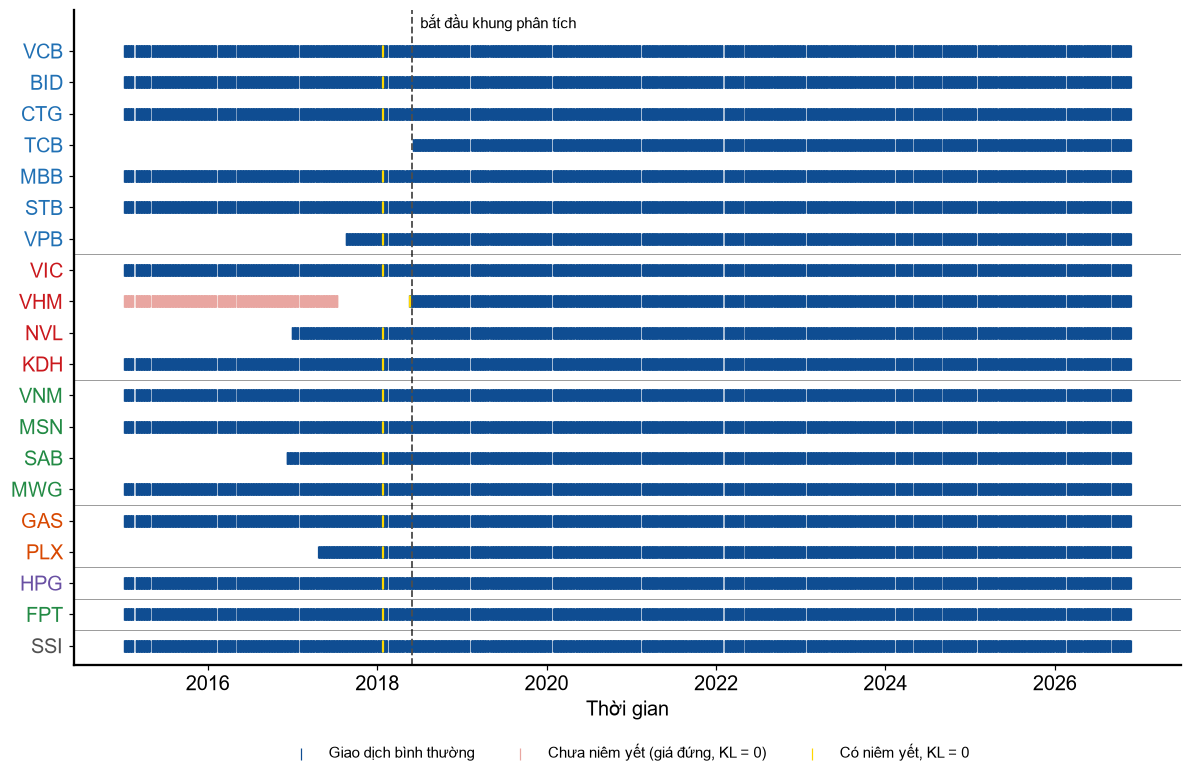

In [8]:
f = con.execute("SELECT symbol, time, is_listed, is_traded FROM daily_features").df()
f["status"] = np.select([~f.is_listed, ~f.is_traded], [0, 1], default=2)
start = cfg.analysis_start.iloc[0]

fig, ax = plt.subplots(figsize=(11, 7.2))
labels = {0: "Chưa niêm yết (giá đứng, KL = 0)", 1: "Có niêm yết, KL = 0", 2: "Giao dịch bình thường"}
colors = {0: U.PALETTE["red_2"], 1: U.PALETTE["highlight"], 2: U.PALETTE["blue_main"]}
for y, sym in enumerate(SYMBOLS):
    d = f[f.symbol == sym]
    for st in (2, 0, 1):
        s = d[d.status == st]
        ax.scatter(s.time, np.full(len(s), y), marker="|", s=70, color=colors[st],
                   label=labels[st] if y == 0 else None, linewidths=0.8)
ax.axvline(start, color=U.PALETTE["gray_dark"], ls="--", lw=1.2)
ax.text(start, -0.9, "  bắt đầu khung phân tích", va="center", fontsize=10)
ax.set_yticks(range(len(SYMBOLS)), SYMBOLS)
for t, s in zip(ax.get_yticklabels(), SYMBOLS): t.set_color(SC[SECTOR[s]])
for i in range(1, len(SYMBOLS)):                       # vạch phân cách ngành
    if SECTOR[SYMBOLS[i]] != SECTOR[SYMBOLS[i - 1]]:
        ax.axhline(i - 0.5, color="black", lw=0.5, alpha=0.5)
ax.set_ylim(len(SYMBOLS) - 0.4, -1.3)                  # mã đầu danh sách ở trên cùng
ax.set_xlabel("Thời gian")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=3, fontsize=10)
U.finalize_figure(fig, "01_data_coverage")
plt.show()

## 6. Kiểm tra hợp lệ giá trị

In [9]:
checks = con.execute("""
    SELECT symbol,
           SUM((open <= 0 OR high <= 0 OR low <= 0 OR close <= 0)::INT) AS gia_khong_duong,
           SUM((high < low)::INT)                                       AS high_nho_hon_low,
           SUM((ABS(ret) > 0.075 AND is_listed)::INT)                   AS vuot_bien_do_7pct,
           SUM((volume < 0)::INT)                                       AS kl_am
    FROM daily_features GROUP BY symbol""").df().set_index("symbol").loc[SYMBOLS].astype(int)
print("Tổng số vi phạm theo từng kiểm tra:", checks.sum().to_dict())
checks

Tổng số vi phạm theo từng kiểm tra: {'gia_khong_duong': 0, 'high_nho_hon_low': 0, 'vuot_bien_do_7pct': 0, 'kl_am': 0}


,gia_khong_duong,high_nho_hon_low,vuot_bien_do_7pct,kl_am
symbol,,,,
VCB,0,0,0,0
BID,0,0,0,0
CTG,0,0,0,0
TCB,0,0,0,0
MBB,0,0,0,0
STB,0,0,0,0
VPB,0,0,0,0
VIC,0,0,0,0
VHM,0,0,0,0


In [10]:
# Lợi suất vượt ±7,5% sau niêm yết: thường do ngày giao dịch đầu tiên hoặc
# điều chỉnh sự kiện quyền chưa khớp hoàn toàn -> liệt kê để kiểm tra thủ công
con.execute("""
    SELECT symbol, time, prev_close, close, ret, volume
    FROM daily_features WHERE ABS(ret) > 0.075 AND is_listed
    ORDER BY symbol, time""").df()

,symbol,time,prev_close,close,ret,volume


## 7. Quyết định xử lý dữ liệu (ghi lại để tái lập)

In [11]:
decisions = pd.DataFrame([
    ("Phiên VHM trước 17/05/2018", "Giá đứng, khối lượng ≈ 0 (chưa niêm yết HOSE)", "Loại khỏi phân tích (cờ is_listed = false)"),
    ("Khung phân tích chung", "TCB niêm yết 04/06/2018, VHM 17/05/2018, VPB 08/2017, NVL 12/2016; 16 mã còn lại có dữ liệu từ 2015 hoặc sớm hơn",
     f"Dùng {start:%d/%m/%Y} → phiên cuối cho mọi mã; TCB thiếu 2 phiên đầu khung (loại bằng dropna khi cần ma trận chung)"),
    ("Mã mới có dữ liệu ngắn hơn lịch sử", "15 mã mới không có giá 'ảo' trước niêm yết trong nguồn VCI", "Dùng nguyên, chỉ cắt theo khung chung"),
    ("Biên độ giá HOSE ±7%", "Lợi suất ngày bị chặn hai đầu", "Giữ nguyên; lưu ý khi ước lượng đuôi (notebook 03)"),
    ("Giá đã điều chỉnh", "Nguồn VCI điều chỉnh theo sự kiện quyền", "Dùng trực tiếp để tính lợi suất"),
    ("Đơn vị", "Giá: nghìn đồng; khối lượng: cổ phiếu", "Giữ nguyên, ghi trong data_dictionary.md"),
], columns=["Vấn đề", "Phát hiện", "Quyết định"])
U.save_table(decisions.set_index("Vấn đề"), "01_cleaning_decisions")
decisions

,Vấn đề,Phát hiện,Quyết định
0,Phiên VHM trước 17/05/2018,"Giá đứng, khối lượng ≈ 0 (chưa niêm yết HOSE)",Loại khỏi phân tích (cờ is_listed = false)
1,Khung phân tích chung,"TCB niêm yết 04/06/2018, VHM 17/05/2018, VPB 0...",Dùng 01/06/2018 → phiên cuối cho mọi mã; TCB t...
2,Mã mới có dữ liệu ngắn hơn lịch sử,15 mã mới không có giá 'ảo' trước niêm yết tro...,"Dùng nguyên, chỉ cắt theo khung chung"
3,Biên độ giá HOSE ±7%,Lợi suất ngày bị chặn hai đầu,Giữ nguyên; lưu ý khi ước lượng đuôi (notebook...
4,Giá đã điều chỉnh,Nguồn VCI điều chỉnh theo sự kiện quyền,Dùng trực tiếp để tính lợi suất
5,Đơn vị,Giá: nghìn đồng; khối lượng: cổ phiếu,"Giữ nguyên, ghi trong data_dictionary.md"
